# Flood SoS simulation analysis

This notebook compares profile configurations across Low-only, High-only, and Mixed strategies. It analyzes mission success, victims rescued before deadlines, DT participation and active service time, pumping-station availability and output, activity-based cost, autonomous Poisson departure requests, health-driven departures, recovery re-admission, and rescue-capacity protection. It reads the simulator outputs `simulation_runs.csv`, `flood_history.csv`, and `simulation_summary.json`.

Profile configuration changes the Poisson request rate. Resilience profiles mediate voluntary membership requests; health-driven transitions come from the generated health and belonging machines. The analysis keeps those causes separate.

In [46]:
from pathlib import Path
import json
import math
import pandas as pd
import matplotlib.pyplot as plt

# Find the project root whether the notebook is launched from the project
# directory or from a child directory such as output/.
candidates = [Path.cwd(), *Path.cwd().parents]
project_dir = next(
    (p for p in candidates if (p / 'output' / 'simulation_runs.csv').exists()),
    None,
)
if project_dir is None:
    raise FileNotFoundError('Could not find output/simulation_runs.csv from the current directory or its parents.')

output_dir = project_dir / 'output'
runs_all = pd.read_csv(output_dir / 'simulation_runs.csv')
flood_all = pd.read_csv(output_dir / 'flood_history.csv')
runs = runs_all.copy()
flood = flood_all.copy()
selected_rescue_sensitivity = 'boat_emphasis'
if 'rescue_sensitivity' in runs.columns:
    runs = runs[runs['rescue_sensitivity'] == selected_rescue_sensitivity].copy()
    flood = flood[flood['rescue_sensitivity'] == selected_rescue_sensitivity].copy()
with (output_dir / 'simulation_summary.json').open(encoding='utf-8') as f:
    summary = json.load(f)

print(f'Project: {project_dir}')
print(f'Runs in selected condition: {len(runs):,} | Flood history rows: {len(flood):,}')
if 'rescue_sensitivity' in runs_all.columns:
    print('Available rescue sensitivity conditions:', sorted(runs_all['rescue_sensitivity'].unique()))
print(f"Conditions in summary: {len(summary.get('aggregates', {}))}")
display(runs.head())
display(flood.head())

Project: c:\Users\lamp6\OneDrive\Documentos\Github\RelTwin\prototype\flood_sos
Runs in selected condition: 270 | Flood history rows: 7,830
Available rescue sensitivity conditions: ['boat_emphasis']
Conditions in summary: 9


,scenario,scenario_name,profile_configuration,rescue_sensitivity,rescue_area_penalty,rescue_capacity_per_boat_step,seed,mission_success,mission_success_target,victims_created,...,tasks_failed_health,tasks_failed_physical,tasks_failed_other,repair_time,repair_requests,repairs_completed,final_water_level,final_flooded_area,final_victims_per_area,pumped_water
0,low_only,Low-only,baseline,boat_emphasis,0.04,3.0,7,False,32,32,...,14,14,0,3.0,2,1,8.25,20.625,0.581818,0.00
1,low_only,Low-only,baseline,boat_emphasis,0.04,3.0,8,False,26,26,...,8,5,0,6.0,2,2,6.09,15.225,0.328407,2.16
2,low_only,Low-only,baseline,boat_emphasis,0.04,3.0,9,False,26,26,...,5,1,0,6.0,2,2,6.69,16.725,0.538117,1.56
3,low_only,Low-only,baseline,boat_emphasis,0.04,3.0,10,False,26,26,...,8,6,0,3.0,1,1,6.81,17.025,0.234949,1.44
4,low_only,Low-only,baseline,boat_emphasis,0.04,3.0,11,True,26,26,...,0,0,0,6.0,2,2,7.65,19.125,0.000000,0.60


,scenario,profile_configuration,seed,time,rescue_sensitivity,rescue_area_penalty,rescue_capacity_per_boat_step,water_level,flooded_area,victims_waiting,victims_rescued,victims_rescued_before_deadline,victims_expired,total_victims,victims_per_area
0,low_only,baseline,7,1,boat_emphasis,0.04,3.0,1.25,3.125,6,2,2,0,8,1.9200
1,low_only,baseline,7,2,boat_emphasis,0.04,3.0,1.50,3.750,6,2,2,0,8,1.6000
2,low_only,baseline,7,3,boat_emphasis,0.04,3.0,1.75,4.375,4,4,4,0,8,0.9143
3,low_only,baseline,7,4,boat_emphasis,0.04,3.0,2.00,5.000,7,7,7,0,14,1.4000
4,low_only,baseline,7,5,boat_emphasis,0.04,3.0,2.25,5.625,5,9,9,0,14,0.8889


## Experimental conditions and summary metrics

The JSON summary contains aggregate results by strategy, departure configuration, and (when enabled) rescue-sensitivity condition. The main plots use the selected condition; the last section compares the full pump/boat sweep.

In [47]:
aggregates = (
    pd.DataFrame.from_dict(summary['aggregates'], orient='index')
      .rename_axis('condition')
      .reset_index()
)
display(aggregates)
print('Strategies:', sorted(runs['scenario'].dropna().unique()))
print('Profile configurations:', sorted(runs['profile_configuration'].dropna().unique()))
print('Seeds per condition (min/max):', runs.groupby(['scenario', 'profile_configuration'])['seed'].nunique().agg(['min', 'max']).to_dict())

,condition,runs,successes,success_rate,mean_victims_rescued_before_deadline,mean_peak_attached_dts,mean_peak_constellation_dts,mean_dt_time,mean_active_dt_time,mean_active_dt_time_by_asset,...,mean_repairs_completed,mean_cost_low,mean_cost_base,mean_cost_high,mean_cost_by_category_base,mean_sos_request_counts,mean_join_request_counts,mean_health_rejoin_counts,mean_task_outcome_counts,mean_dt_time_by_asset
0,low_only/baseline/boat_emphasis,30,4,0.133333,20.000000,5.0,3.966667,144.733333,70.900000,"{'boat': 43.56666666666667, 'drone': 11.733333...",...,1.733333,128.834067,157.871668,215.743335,"{'Data activities': 17.385333333333335, 'IT in...","{'capacity_deferred': 1.2666666666666666, 'com...","{'completed': 2.7, 'generated': 4.4, 'machine_...","{'completed': 0.0, 'eligible_departures': 2.1,...","{'attempted': 60.03333333333333, 'failed_healt...","{'boat': 90.0, 'drone': 30.0, 'pump': 24.73333..."
1,low_only/reduced_departure/boat_emphasis,30,3,0.100000,19.433333,5.0,4.166667,144.033333,93.766667,"{'boat': 56.93333333333333, 'drone': 16.7, 'pu...",...,1.400000,128.318935,156.859670,213.719341,"{'Data activities': 17.296, 'IT infrastructure...","{'capacity_deferred': 0.8666666666666667, 'com...","{'completed': 2.7333333333333334, 'generated':...","{'completed': 0.0, 'eligible_departures': 1.53...","{'attempted': 80.2, 'failed_health': 17.133333...","{'boat': 90.0, 'drone': 30.0, 'pump': 24.03333..."
2,low_only/increased_departure/boat_emphasis,30,1,0.033333,22.433333,5.0,3.466667,147.800000,45.000000,"{'boat': 31.566666666666666, 'drone': 6.7, 'pu...",...,1.500000,129.284394,158.754155,217.508309,"{'Data activities': 17.730666666666668, 'IT in...","{'capacity_deferred': 2.7333333333333334, 'com...","{'completed': 2.933333333333333, 'generated': ...","{'completed': 0.0, 'eligible_departures': 1.73...","{'attempted': 38.03333333333333, 'failed_healt...","{'boat': 90.0, 'drone': 30.0, 'pump': 27.8}"
3,high_only/baseline/boat_emphasis,30,1,0.033333,20.100000,5.0,4.666667,144.533333,115.400000,"{'boat': 68.26666666666667, 'drone': 24.033333...",...,3.900000,131.953868,164.125035,228.250070,"{'Data activities': 17.30933333333333, 'IT inf...","{'capacity_deferred': 0.4666666666666667, 'com...","{'completed': 4.1, 'generated': 4.266666666666...","{'completed': 2.8, 'eligible_departures': 3.73...","{'attempted': 77.1, 'failed_health': 15.866666...","{'boat': 89.86666666666666, 'drone': 30.0, 'pu..."
4,high_only/reduced_departure/boat_emphasis,30,0,0.000000,19.433333,5.0,4.800000,144.700000,119.433333,"{'boat': 69.8, 'drone': 24.866666666666667, 'p...",...,3.933333,131.863201,163.944702,227.889404,"{'Data activities': 17.317999999999998, 'IT in...","{'capacity_deferred': 0.26666666666666666, 'co...","{'completed': 3.8333333333333335, 'generated':...","{'completed': 2.9, 'eligible_departures': 3.73...","{'attempted': 78.7, 'failed_health': 16.433333...","{'boat': 89.93333333333334, 'drone': 30.0, 'pu..."
5,high_only/increased_departure/boat_emphasis,30,3,0.100000,21.500000,5.0,4.366667,145.300000,103.166667,"{'boat': 63.13333333333333, 'drone': 22.733333...",...,3.733333,131.845734,163.905135,227.810270,"{'Data activities': 17.43, 'IT infrastructure'...","{'capacity_deferred': 0.5333333333333333, 'com...","{'completed': 4.0, 'generated': 4.166666666666...","{'completed': 3.0, 'eligible_departures': 3.5,...","{'attempted': 70.16666666666667, 'failed_healt...","{'boat': 89.96666666666667, 'drone': 30.0, 'pu..."
6,mixed/baseline/boat_emphasis,30,16,0.533333,21.733333,5.0,4.066667,144.133333,85.500000,"{'boat': 53.1, 'drone': 14.433333333333334, 'p...",...,3.100000,129.662234,159.537668,219.075337,"{'Data activities': 17.329333333333334, 'IT in...","{'capacity_deferred': 0.3333333333333333, 'com...","{'completed': 3.0, 'generated': 4.3, 'machine_...","{'completed': 2.7666666666666666, 'eligible_de...","{'attempted': 68.5, 'failed_health': 13.6, 'fa...","{'boat': 88.83333333333333, 'drone': 29.166666..."
7,mixed/reduced_departure/boat_emphasis

Strategies: ['high_only', 'low_only', 'mixed']
Profile configurations: ['baseline', 'increased_departure', 'reduced_departure']
Seeds per condition (min/max): {'min': 30, 'max': 30}


## Mission success rate

Success rate is the proportion of runs whose rescued-victim count met the configured mission target. This plot is recalculated from run-level records.

,scenario,profile_configuration,success_rate,valid_runs
0,high_only,baseline,0.033333,30
1,high_only,increased_departure,0.100000,30
2,high_only,reduced_departure,0.000000,30
3,low_only,baseline,0.133333,30
4,low_only,increased_departure,0.033333,30
5,low_only,reduced_departure,0.100000,30
6,mixed,baseline,0.533333,30
7,mixed,increased_departure,0.466667,30
8,mixed,reduced_departure,0.533333,30


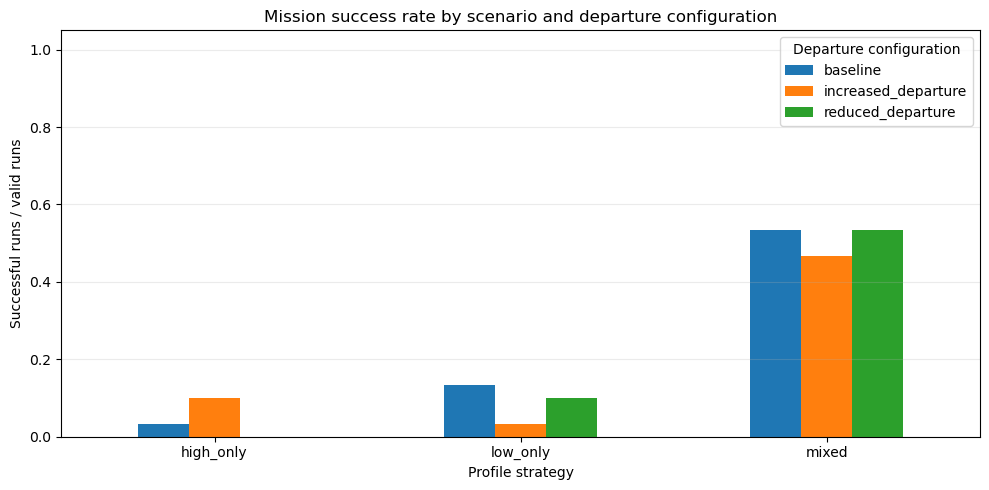

In [48]:
success = (
    runs.groupby(['scenario', 'profile_configuration'], observed=True)['mission_success']
        .agg(success_rate='mean', valid_runs='size')
        .reset_index()
)
display(success)
success_pivot = success.pivot(index='scenario', columns='profile_configuration', values='success_rate')
ax = success_pivot.plot(kind='bar', figsize=(10, 5), ylim=(0, 1.05), rot=0)
ax.set(title='Mission success rate by scenario and departure configuration', xlabel='Profile strategy', ylabel='Successful runs / valid runs')
ax.legend(title='Departure configuration')
ax.grid(axis='y', alpha=.25)
plt.tight_layout()
plt.show()

## Victims rescued and DT participation

These views show run-to-run mission outcome variation and the number of DTs participating. Peak attached DTs is the peak count during a run; DT-time sums attached time across DTs. The cost analysis below reports monetary-style estimates separately.

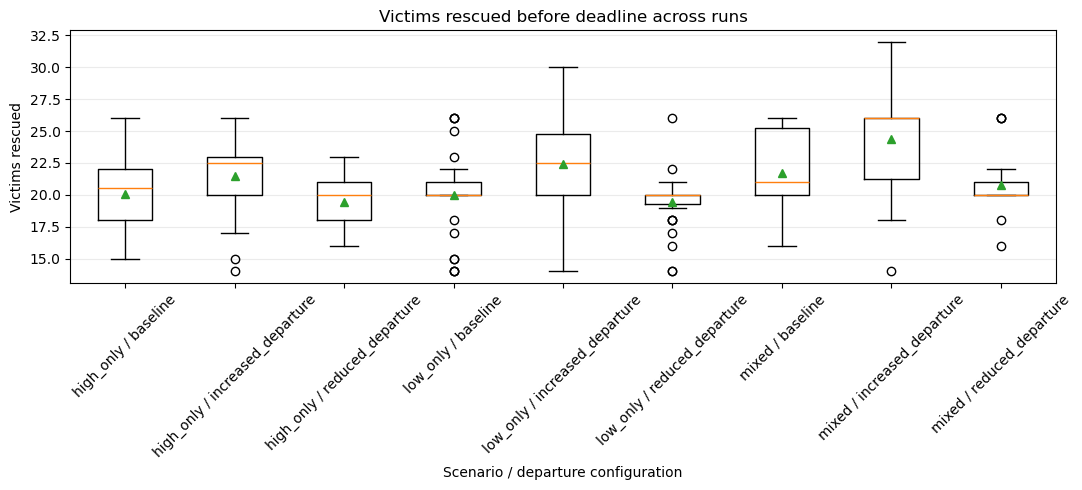

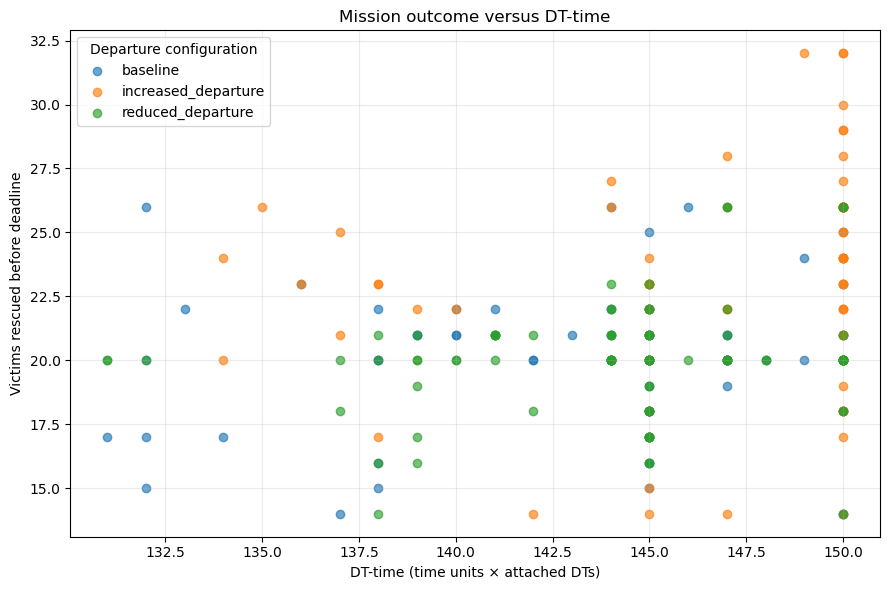

In [49]:
runs['condition_label'] = runs['scenario'] + ' / ' + runs['profile_configuration']
condition_order = sorted(runs['condition_label'].unique())
groups = [runs.loc[runs['condition_label'] == label, 'victims_rescued_before_deadline'].dropna().values for label in condition_order]
fig, ax = plt.subplots(figsize=(max(11, len(condition_order) * .8), 5))
ax.boxplot(groups, tick_labels=condition_order, showmeans=True)
ax.set(title='Victims rescued before deadline across runs', xlabel='Scenario / departure configuration', ylabel='Victims rescued')
ax.tick_params(axis='x', rotation=45)
ax.grid(axis='y', alpha=.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 6))
for config, subset in runs.groupby('profile_configuration'):
    ax.scatter(subset['dt_time'], subset['victims_rescued_before_deadline'], label=config, alpha=.65)
ax.set(title='Mission outcome versus DT-time', xlabel='DT-time (time units × attached DTs)', ylabel='Victims rescued before deadline')
ax.legend(title='Departure configuration')
ax.grid(alpha=.25)
plt.tight_layout()
plt.show()

## Flood and rescue trajectories

Each panel shows the mean water level over time for one profile strategy. Shading is a 95% confidence interval around the mean across seeds at each time point (normal approximation). This describes variation across simulation runs, not uncertainty in real-world flood data.

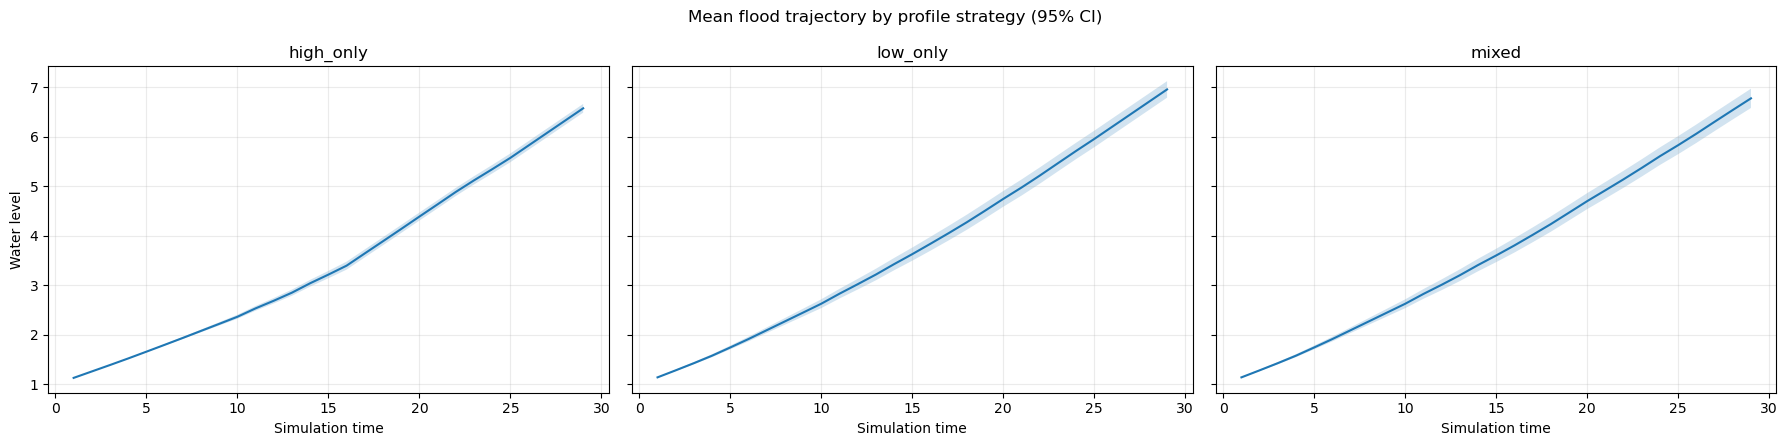

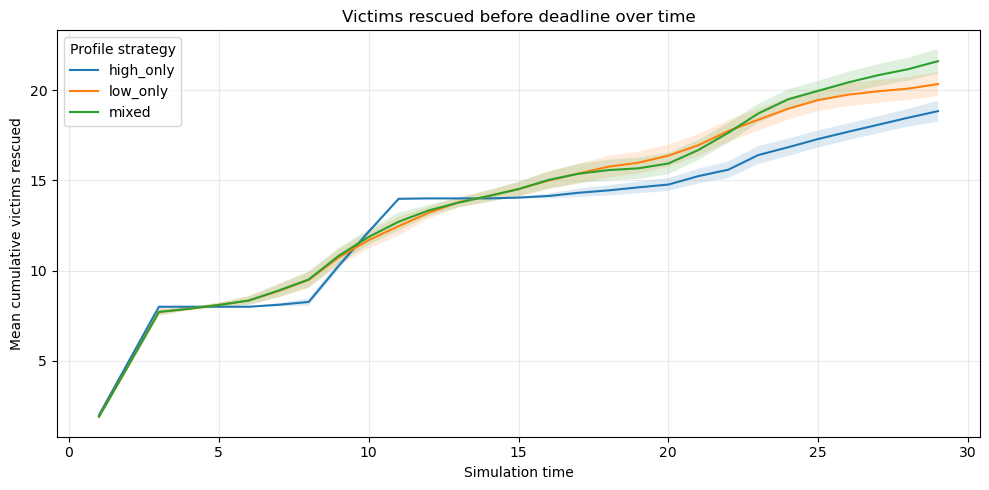

In [50]:
strategies = sorted(flood['scenario'].dropna().unique())
fig, axes = plt.subplots(1, len(strategies), figsize=(6 * len(strategies), 4.5), sharey=True)
if len(strategies) == 1:
    axes = [axes]
for ax, strategy in zip(axes, strategies):
    part = flood[flood['scenario'] == strategy]
    stats = part.groupby('time')['water_level'].agg(['mean', 'std', 'count'])
    ci = 1.96 * stats['std'].fillna(0) / stats['count'].clip(lower=1).pow(.5)
    ax.plot(stats.index, stats['mean'], label='Mean water level')
    ax.fill_between(stats.index, stats['mean'] - ci, stats['mean'] + ci, alpha=.2)
    ax.set(title=strategy, xlabel='Simulation time')
    ax.grid(alpha=.25)
axes[0].set_ylabel('Water level')
fig.suptitle('Mean flood trajectory by profile strategy (95% CI)')
plt.tight_layout()
plt.show()

rescues = flood.groupby(['scenario', 'time'])['victims_rescued_before_deadline'].agg(['mean', 'std', 'count']).reset_index()
fig, ax = plt.subplots(figsize=(10, 5))
for strategy, part in rescues.groupby('scenario'):
    part = part.sort_values('time')
    ci = 1.96 * part['std'].fillna(0) / part['count'].clip(lower=1).pow(.5)
    ax.plot(part['time'], part['mean'], label=strategy)
    ax.fill_between(part['time'], part['mean'] - ci, part['mean'] + ci, alpha=.15)
ax.set(title='Victims rescued before deadline over time', xlabel='Simulation time', ylabel='Mean cumulative victims rescued')
ax.legend(title='Profile strategy')
ax.grid(alpha=.25)
plt.tight_layout()
plt.show()

## Generated health transitions

The JSON run records include health and belonging transitions emitted by the generated state machines. This table counts environmental fault and recovery transitions when those events are present in the saved outputs. A zero count may mean the output files were generated before fault injection was added.

,scenario,profile_configuration,event_type,count
0,high_only,baseline,Environmental fault,693
1,high_only,baseline,Recovery,117
2,high_only,increased_departure,Environmental fault,595
3,high_only,increased_departure,Recovery,112
4,high_only,reduced_departure,Environmental fault,721
5,high_only,reduced_departure,Recovery,118
6,low_only,baseline,Environmental fault,417
7,low_only,baseline,Recovery,52
8,low_only,increased_departure,Environmental fault,246
9,low_only,increased_departure,Recovery,45


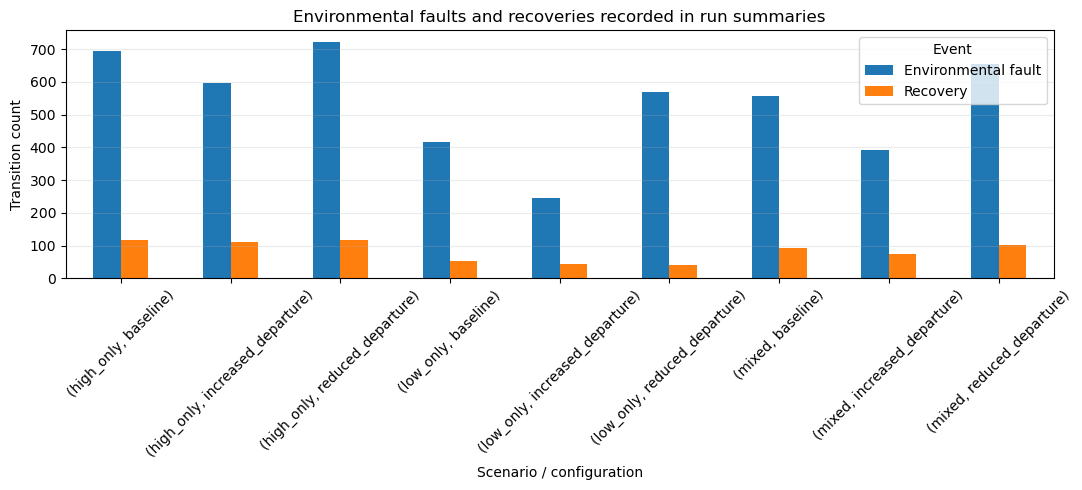

In [51]:
transition_rows = []
for run in summary.get('runs', []):
    for twin, transitions in run.get('state_transitions', {}).items():
        for transition in transitions:
            cause = str(transition.get('cause', ''))
            if cause.startswith('environmental_fault:'):
                event_type = 'Environmental fault'
            elif cause.startswith('repair:'):
                event_type = 'Recovery'
            else:
                continue
            transition_rows.append({
                'scenario': run.get('scenario'),
                'profile_configuration': run.get('profile_configuration'),
                'twin': twin,
                'event_type': event_type,
                'cause': cause,
                'from_health': transition.get('from', {}).get('health'),
                'to_health': transition.get('to', {}).get('health'),
            })
transition_df = pd.DataFrame(transition_rows)
if transition_df.empty:
    print('No environmental fault or recovery transitions found in simulation_summary.json.')
else:
    transition_counts = (transition_df.groupby(['scenario', 'profile_configuration', 'event_type']).size().rename('count').reset_index())
    display(transition_counts)
    chart = transition_counts.pivot_table(index=['scenario', 'profile_configuration'], columns='event_type', values='count', fill_value=0)
    ax = chart.plot(kind='bar', figsize=(11, 5))
    ax.set(title='Environmental faults and recoveries recorded in run summaries', xlabel='Scenario / configuration', ylabel='Transition count')
    ax.tick_params(axis='x', rotation=45)
    ax.legend(title='Event')
    ax.grid(axis='y', alpha=.25)
    plt.tight_layout()
    plt.show()

## Membership causes and minimum rescue-boat capacity

SoS-autonomy requests are generated by the configured Poisson process and then mediated by the resilience profile. Health-related departures are counted separately because they originate in health-state transitions. Capacity deferrals show the minimum number of rescue boats required by the departure guard; this is based on remaining victims, time to deadline, expected boat throughput, and flooded area.

,scenario,profile_configuration,event,count
0,high_only,baseline,health_related_departure,117
1,high_only,baseline,rescue_capacity_shortfall,227
2,high_only,baseline,sos_departure_completed,35
3,high_only,baseline,sos_departure_deferred_for_capacity,14
4,high_only,baseline,sos_departure_denied_by_profile,202
...,...,...,...,...
58,mixed,reduced_departure,sos_departure_completed,60
59,mixed,reduced_departure,sos_departure_deferred_for_capacity,6
60,mixed,reduced_departure,sos_departure_denied_by_profile,40
61,mixed,reduced_departure,sos_departure_request,106


event                            health_related_departure  \
scenario  profile_configuration                             
high_only baseline                                  117.0   
          increased_departure                       107.0   
          reduced_departure                         114.0   
low_only  baseline                                   64.0   
          increased_departure                        56.0   
          reduced_departure                          47.0   
mixed     baseline                                   98.0   
          increased_departure                        89.0   
          reduced_departure                         106.0   

event                            rescue_capacity_shortfall  \
scenario  profile_configuration                              
high_only baseline                                   227.0   
          increased_departure                        212.0   
          reduced_departure                          234.0   
low_only  baseline                                   232.0   
          increased_departure                        322.0   
          reduced_departure                          218.0   
mixed     baseline                                   143.0   
          increased_departure                        243.0   
          reduced_departure                          116.0   

event                            sos_departure_completed  \
scenario  profile_configuration                            
high_only baseline                                  35.0   
          increased_departure                       72.0   
          reduced_departure                         21.0   
low_only  baseline                                 115.0   
          increased_departure                      139.0   
          reduced_departure                         77.0   
mixed     baseline                                 100.0   
          increased_departure                      141.0   
          reduced_departure                         60.0   

event                            sos_departure_deferred_for_capacity  \
scenario  profile_configuration                                        
high_only baseline                                              14.0   
          increased_departure                                   16.0   
          reduced_departure                                      8.0   
low_only  baseline                                              38.0   
          increased_departure                                   82.0   
          reduced_departure                                     26.0   
mixed     baseline                                              10.0   
          increased_departure                                   38.0   
          reduced_departure                                      6.0   

event                            sos_departure_denied_by_profile  \
scenario  profile_configuration                                    
high_only baseline                                         202.0   
          increased_departure                              363.0   
          reduced_departure                                111.0   
low_only  baseline                                          21.0   
          increased_departure                               26.0   
          reduced_departure                                 14.0   
mixed     baseline                                          67.0   
          increased_departure                              102.0   
          reduced_departure                                 40.0   

event                            sos_departure_request  \
scenario  profile_configuration                          
high_only baseline                               252.0   
          increased_departure                    451.0   
          reduced_departure                      141.0   
low_only  baseline                               174.0   
          increased_departure                    247.0   
          reduced_departure         

,scenario,profile_configuration,minimum_boats,observations
0,high_only,baseline,1.0,241
1,high_only,increased_departure,1.0,228
2,high_only,reduced_departure,1.0,242
3,low_only,baseline,1.0,270
4,low_only,increased_departure,1.0,401
5,low_only,increased_departure,2.0,2
6,low_only,increased_departure,3.0,1
7,low_only,reduced_departure,1.0,244
8,mixed,baseline,1.0,153
9,mixed,increased_departure,1.0,278


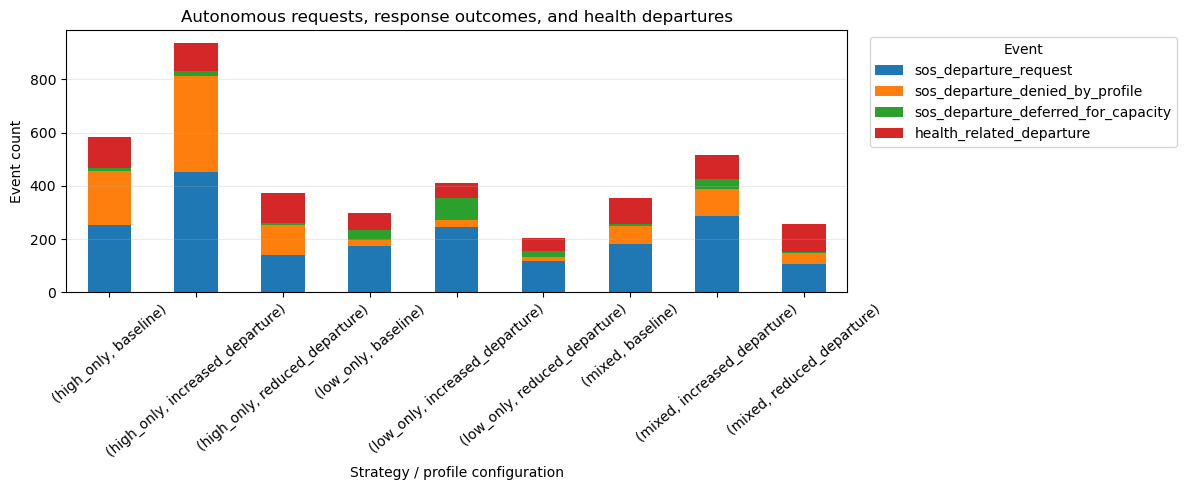

In [52]:
event_rows = []
for run in summary.get('runs', []):
    for event in run.get('coordinator_events', []):
        kind = event.get('event')
        if kind in {'sos_departure_request', 'sos_departure_denied_by_profile',
                    'sos_departure_deferred_for_capacity', 'sos_departure_submitted_to_bm',
                    'sos_departure_completed', 'health_related_departure',
                    'rescue_capacity_shortfall'}:
            event_rows.append({
                'scenario': run.get('scenario'),
                'profile_configuration': run.get('profile_configuration'),
                'event': kind,
                'unit': event.get('unit'),
                'profile': event.get('profile'),
                'minimum_boats': event.get('minimum_boats', event.get('required_boats')),
                'boats_after_departure': event.get('boats_after_departure'),
            })
events_df = pd.DataFrame(event_rows)
if events_df.empty:
    print('No membership or capacity events found in the loaded summary.')
else:
    membership_counts = (events_df.groupby(['scenario', 'profile_configuration', 'event'])
                         .size().rename('count').reset_index())
    display(membership_counts)
    count_pivot = membership_counts.pivot_table(
        index=['scenario', 'profile_configuration'], columns='event', values='count', fill_value=0)
    display(count_pivot)
    capacity_events = events_df[events_df['event'].isin(
        ['sos_departure_deferred_for_capacity', 'rescue_capacity_shortfall'])]
    if not capacity_events.empty and capacity_events['minimum_boats'].notna().any():
        display(capacity_events.groupby(['scenario', 'profile_configuration', 'minimum_boats'])
                .size().rename('observations').reset_index())
    else:
        print('No logged minimum-boat deferrals or capacity shortfalls in these runs.')

    plot_events = ['sos_departure_request', 'sos_departure_denied_by_profile',
                   'sos_departure_deferred_for_capacity', 'health_related_departure']
    plot_data = count_pivot.reindex(columns=plot_events, fill_value=0)
    ax = plot_data.plot(kind='bar', stacked=True, figsize=(12, 5))
    ax.set(title='Autonomous requests, response outcomes, and health departures',
           xlabel='Strategy / profile configuration', ylabel='Event count')
    ax.tick_params(axis='x', rotation=40)
    ax.legend(title='Event', bbox_to_anchor=(1.02, 1), loc='upper left')
    ax.grid(axis='y', alpha=.25)
    plt.tight_layout()
    plt.show()

## DT count, estimated cost, and mission success

The primary scenario comparison is success rate: successful runs divided by valid runs, where success is based on victims rescued before their deadlines. Peak attached DT count and DT-time show participation. Costs use the simulator’s activity-based estimate; base cost is shown here, with low/high sensitivity columns retained in the run data and JSON. Costs should be interpreted as illustrative until rates are calibrated.

,scenario,profile_configuration,runs,success_rate,mean_rescued,mean_peak_attached_dts,mean_dt_time,mean_cost_base,mean_cost_low,mean_cost_high
0,high_only,baseline,30,0.033333,20.100000,5.0,144.533333,164.125035,131.953868,228.250070
1,high_only,increased_departure,30,0.100000,21.500000,5.0,145.300000,163.905135,131.845734,227.810270
2,high_only,reduced_departure,30,0.000000,19.433333,5.0,144.700000,163.944702,131.863201,227.889404
3,low_only,baseline,30,0.133333,20.000000,5.0,144.733333,157.871668,128.834067,215.743335
4,low_only,increased_departure,30,0.033333,22.433333,5.0,147.800000,158.754155,129.284394,217.508309
5,low_only,reduced_departure,30,0.100000,19.433333,5.0,144.033333,156.859670,128.318935,213.719341
6,mixed,baseline,30,0.533333,21.733333,5.0,144.133333,159.537668,129.662234,219.075337
7,mixed,increased_departure,30,0.466667,24.400000,5.0,147.833333,160.025989,129.914561,220.051977
8,mixed,reduced_departure,30,0.533333,20.766667,5.0,143.866667,159.144103,129.460035,218.288207


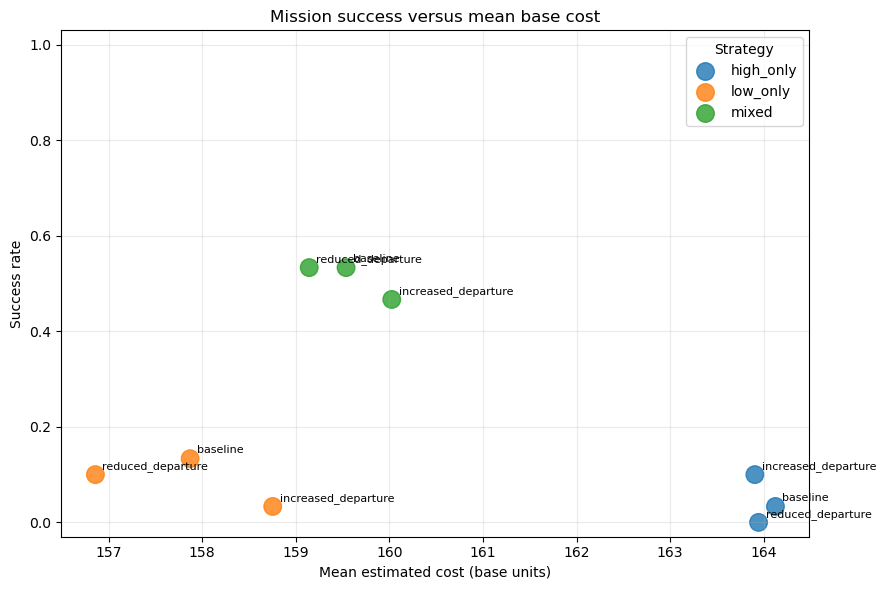

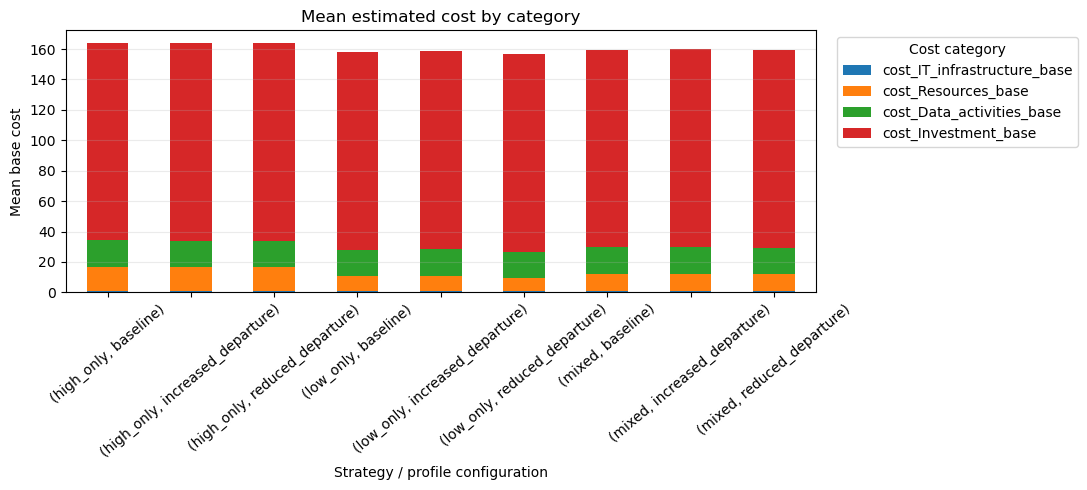

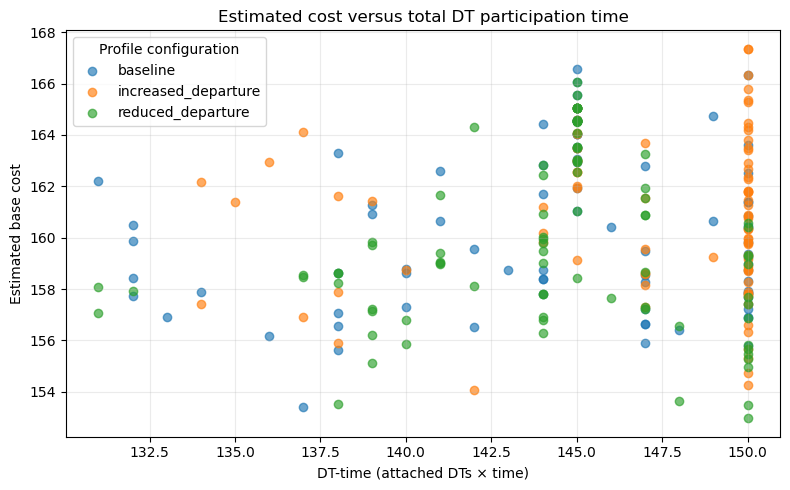

In [53]:
comparison = (runs.groupby(['scenario', 'profile_configuration'], observed=True)
    .agg(runs=('mission_success', 'size'), success_rate=('mission_success', 'mean'),
         mean_rescued=('victims_rescued_before_deadline', 'mean'),
         mean_peak_attached_dts=('peak_attached_dts', 'mean'),
         mean_dt_time=('dt_time', 'mean'),
         mean_cost_base=('cost_total_base', 'mean'),
         mean_cost_low=('cost_total_low', 'mean'),
         mean_cost_high=('cost_total_high', 'mean'))
    .reset_index())
display(comparison)

# A cost-versus-success view: each point is a strategy/configuration condition.
fig, ax = plt.subplots(figsize=(9, 6))
for strategy, part in comparison.groupby('scenario'):
    ax.scatter(part['mean_cost_base'], part['success_rate'],
               s=70 + 18 * part['mean_peak_attached_dts'], label=strategy, alpha=.8)
    for _, row in part.iterrows():
        ax.annotate(row['profile_configuration'],
                    (row['mean_cost_base'], row['success_rate']), xytext=(5, 4),
                    textcoords='offset points', fontsize=8)
ax.set(title='Mission success versus mean base cost', xlabel='Mean estimated cost (base units)',
       ylabel='Success rate', ylim=(-.03, 1.03))
ax.legend(title='Strategy')
ax.grid(alpha=.25)
plt.tight_layout()
plt.show()

cost_columns = ['cost_IT_infrastructure_base', 'cost_Resources_base',
                'cost_Data_activities_base', 'cost_Investment_base']
if set(cost_columns).issubset(runs.columns):
    category_cost = runs.groupby(['scenario', 'profile_configuration'], observed=True)[cost_columns].mean()
    ax = category_cost.plot(kind='bar', stacked=True, figsize=(11, 5))
    ax.set(title='Mean estimated cost by category', xlabel='Strategy / profile configuration',
           ylabel='Mean base cost')
    ax.tick_params(axis='x', rotation=40)
    ax.legend(title='Cost category', bbox_to_anchor=(1.02, 1), loc='upper left')
    ax.grid(axis='y', alpha=.25)
    plt.tight_layout()
    plt.show()

# DT participation has a direct time relationship to recurring service cost drivers.
fig, ax = plt.subplots(figsize=(8, 5))
for config, part in runs.groupby('profile_configuration'):
    ax.scatter(part['dt_time'], part['cost_total_base'], label=config, alpha=.65)
ax.set(title='Estimated cost versus total DT participation time',
       xlabel='DT-time (attached DTs × time)', ylabel='Estimated base cost')
ax.legend(title='Profile configuration')
ax.grid(alpha=.25)
plt.tight_layout()
plt.show()

## Pump availability and health-recovery re-admission

Attached DT-time can include Passive DTs that are not currently providing service. This section compares Active DT-time with attached time, and reports the pumping station's Active time, service-eligible time, and delivered pump output. It also summarizes health-related departures and the profile-mediated readmission attempts made after repair.

,scenario,profile_configuration,mean_active_dt_time,mean_pump_active_time,mean_pump_service_time,mean_pumped_water
0,high_only,baseline,115.400000,23.100000,14.566667,1.748
1,high_only,increased_departure,103.166667,17.300000,12.133333,1.456
2,high_only,reduced_departure,119.433333,24.766667,15.233333,1.828
3,low_only,baseline,70.900000,15.600000,11.866667,1.424
4,low_only,increased_departure,45.000000,6.733333,5.900000,0.708
5,low_only,reduced_departure,93.766667,20.133333,14.633333,1.756
6,mixed,baseline,85.500000,17.966667,13.966667,1.676
7,mixed,increased_departure,62.966667,7.800000,6.333333,0.760
8,mixed,reduced_departure,99.166667,23.200000,17.600000,2.112


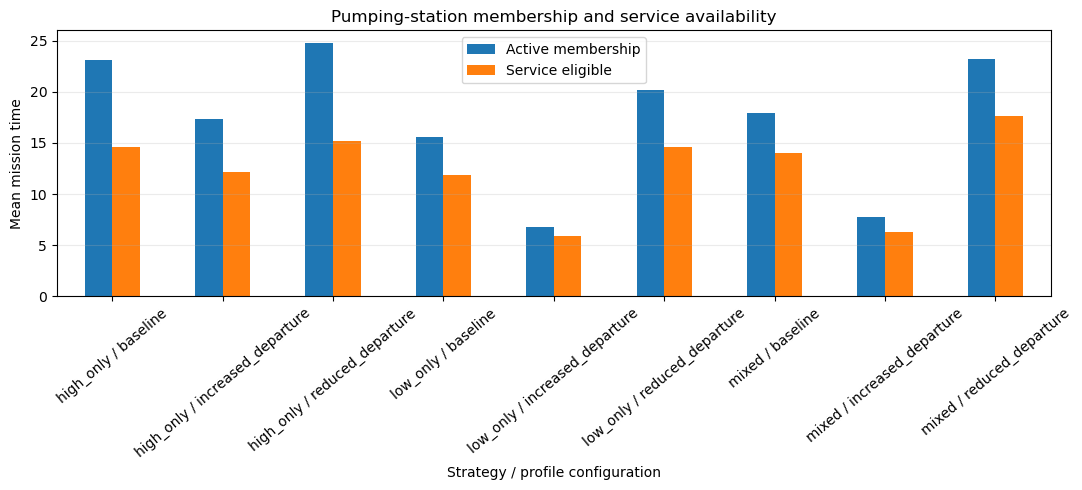

,scenario,profile_configuration,event,count
0,high_only,baseline,health_rejoin_completed,84
1,high_only,baseline,health_rejoin_denied_by_profile,7
2,high_only,baseline,health_rejoin_request,91
3,high_only,baseline,health_related_departure,117
4,high_only,increased_departure,health_rejoin_completed,90
5,high_only,increased_departure,health_rejoin_denied_by_profile,2
6,high_only,increased_departure,health_rejoin_request,88
7,high_only,increased_departure,health_related_departure,107
8,high_only,reduced_departure,health_rejoin_completed,87
9,high_only,reduced_departure,health_rejoin_denied_by_profile,1


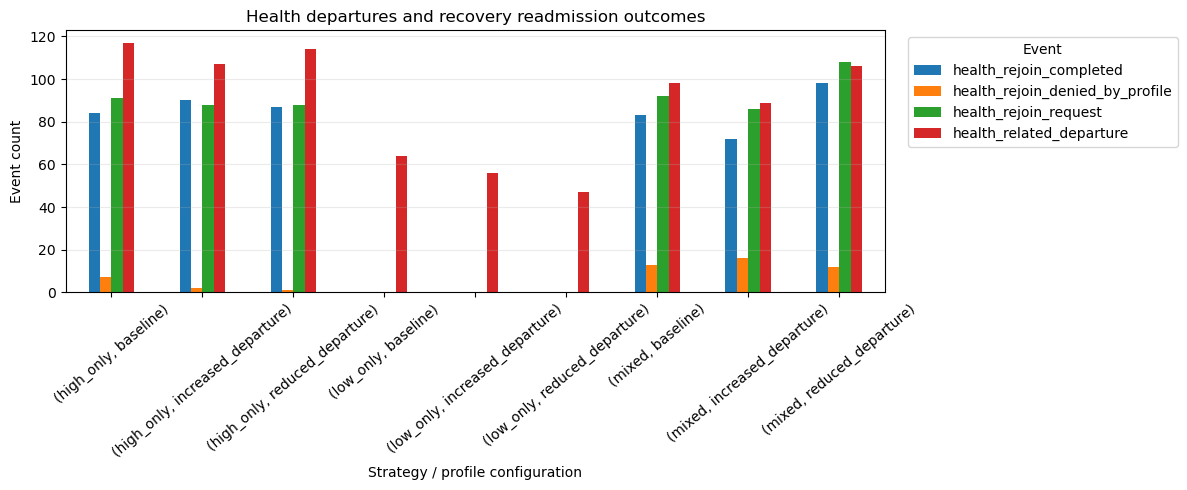

In [54]:
pump_columns = ['pumping_station_active_time', 'pumping_station_service_time', 'pumped_water']
if set(pump_columns + ['active_dt_time']) .issubset(runs.columns):
    pump_summary = (runs.groupby(['scenario', 'profile_configuration'], observed=True)
        .agg(mean_active_dt_time=('active_dt_time', 'mean'),
             mean_pump_active_time=('pumping_station_active_time', 'mean'),
             mean_pump_service_time=('pumping_station_service_time', 'mean'),
             mean_pumped_water=('pumped_water', 'mean'))
        .reset_index())
    display(pump_summary)
    pump_summary['condition'] = pump_summary['scenario'] + ' / ' + pump_summary['profile_configuration']
    ax = pump_summary.set_index('condition')[['mean_pump_active_time', 'mean_pump_service_time']].plot(
        kind='bar', figsize=(11, 5))
    ax.set(title='Pumping-station membership and service availability',
           xlabel='Strategy / profile configuration', ylabel='Mean mission time')
    ax.tick_params(axis='x', rotation=40)
    ax.legend(['Active membership', 'Service eligible'])
    ax.grid(axis='y', alpha=.25)
    plt.tight_layout()
    plt.show()
else:
    print('The loaded run CSV predates the pump active/service-time metrics. Rerun the simulator to populate them.')

rejoin_rows = []
for run in summary.get('runs', []):
    for event in run.get('coordinator_events', []):
        kind = event.get('event', '')
        if kind.startswith('health_rejoin_') or kind == 'health_related_departure':
            rejoin_rows.append({'scenario': run.get('scenario'),
                'profile_configuration': run.get('profile_configuration'),
                'event': kind, 'unit': event.get('unit'), 'profile': event.get('profile'),
                'time': event.get('time'), 'path': event.get('path')})
rejoin_df = pd.DataFrame(rejoin_rows)
if rejoin_df.empty:
    print('No health departures or health-recovery re-admission events found in the loaded summary.')
else:
    display(rejoin_df.groupby(['scenario', 'profile_configuration', 'event']).size()
            .rename('count').reset_index())
    rejoin_counts = rejoin_df.groupby(['scenario', 'profile_configuration', 'event']).size()
    rejoin_counts = rejoin_counts.unstack('event', fill_value=0)
    ax = rejoin_counts.plot(kind='bar', figsize=(12, 5))
    ax.set(title='Health departures and recovery readmission outcomes',
           xlabel='Strategy / profile configuration', ylabel='Event count')
    ax.tick_params(axis='x', rotation=40)
    ax.legend(title='Event', bbox_to_anchor=(1.02, 1), loc='upper left')
    ax.grid(axis='y', alpha=.25)
    plt.tight_layout()
    plt.show()

## Pump-versus-boat sensitivity

The earlier plots use `selected_rescue_sensitivity` (default `boat_emphasis`). This section compares all matched 2-by-2 conditions when outputs were generated with `--rescue-sensitivity all`.

,scenario,profile_configuration,rescue_sensitivity,runs,success_rate,mean_rescued,mean_pumped_water,mean_pump_service_time
0,high_only,baseline,boat_emphasis,30,0.033333,20.100000,1.748,14.566667
1,high_only,increased_departure,boat_emphasis,30,0.100000,21.500000,1.456,12.133333
2,high_only,reduced_departure,boat_emphasis,30,0.000000,19.433333,1.828,15.233333
3,low_only,baseline,boat_emphasis,30,0.133333,20.000000,1.424,11.866667
4,low_only,increased_departure,boat_emphasis,30,0.033333,22.433333,0.708,5.900000
5,low_only,reduced_departure,boat_emphasis,30,0.100000,19.433333,1.756,14.633333
6,mixed,baseline,boat_emphasis,30,0.533333,21.733333,1.676,13.966667
7,mixed,increased_departure,boat_emphasis,30,0.466667,24.400000,0.760,6.333333
8,mixed,reduced_departure,boat_emphasis,30,0.533333,20.766667,2.112,17.600000


,rescue_sensitivity,rescue_area_penalty,rescue_capacity_per_boat_step,runs,success_rate,mean_rescued
0,boat_emphasis,0.04,3.0,270,0.214815,21.088889


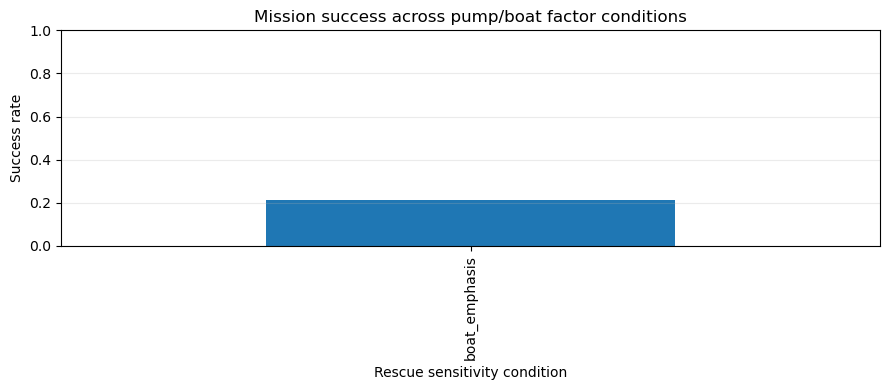

In [55]:
if 'rescue_sensitivity' not in runs_all.columns:
    print('These outputs predate rescue-sensitivity factors. Rerun with --rescue-sensitivity all.')
else:
    rescue_sensitivity_summary = (runs_all.groupby(
        ['scenario', 'profile_configuration', 'rescue_sensitivity'], observed=True
    ).agg(runs=('mission_success', 'size'),
          success_rate=('mission_success', 'mean'),
          mean_rescued=('victims_rescued_before_deadline', 'mean'),
          mean_pumped_water=('pumped_water', 'mean'),
          mean_pump_service_time=('pumping_station_service_time', 'mean'))
      .reset_index())
    display(rescue_sensitivity_summary)
    factor_summary = (runs_all.groupby(
        ['rescue_sensitivity', 'rescue_area_penalty', 'rescue_capacity_per_boat_step'], observed=True
    ).agg(runs=('mission_success', 'size'),
          success_rate=('mission_success', 'mean'),
          mean_rescued=('victims_rescued_before_deadline', 'mean'))
      .reset_index())
    display(factor_summary)
    ax = factor_summary.plot(x='rescue_sensitivity', y='success_rate', kind='bar',
                             figsize=(9, 4), legend=False, ylim=(0, 1))
    ax.set(title='Mission success across pump/boat factor conditions',
           xlabel='Rescue sensitivity condition', ylabel='Success rate')
    ax.grid(axis='y', alpha=.25)
    plt.tight_layout()
    plt.show()